<a href="https://colab.research.google.com/github/AliGulzar-ml/dsa405-project/blob/main/Project/DSA405_002_FA26_P4_agulzar2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# P4: Project Synthesis — Analysis

**Name:** Ali Gulzar  
**Unity ID:** agulzar2  
**Course:** DSA 405-002, Fall 2026  
**Project:** Temperature near Cushing and WTI crude-oil price changes

**Research question:** Is there an association between daily average temperature near Cushing, Oklahoma, and daily percentage changes in the Cushing WTI crude-oil spot price from 2015 through 2025?

### How the notebooks fit together

| Step | Notebook | Input | Output |
|---|---|---|---|
| 1 | `DSA405_002_FA26_P3_agulzar2.ipynb` | `data/raw/noaa_stillwater_daily_2015_2025.csv` and the cached EIA response in `data/raw/` | `data/processed/temperature_wti_join_2015_2025.csv` |
| 2 | **this notebook** | `data/processed/temperature_wti_join_2015_2025.csv` | the figures in `figures/` and every number quoted in the P4 report |

P2 documents the NOAA cleaning rules and P3 documents the acquisition, the join, and the verification suite. This notebook re-checks the joined table before using it, then tests the question several ways so that a single fragile statistic does not carry the conclusion.

## 1. Setup

In [1]:
from pathlib import Path
import os
import subprocess

# Work from the Project folder whether the notebook runs in a local clone or in Colab.
if Path("data/processed").exists():
    PROJECT_DIR = Path.cwd()
elif Path("Project/data/processed").exists():
    PROJECT_DIR = Path("Project").resolve()
else:
    REPO_DIR = Path("/content/dsa405-project")
    if not REPO_DIR.exists():
        subprocess.run(
            ["git", "clone", "https://github.com/AliGulzar-ml/dsa405-project.git", str(REPO_DIR)],
            check=True,
        )
    PROJECT_DIR = REPO_DIR / "Project"

os.chdir(PROJECT_DIR)
print("Working directory:", Path.cwd())

Working directory: /tmp/claude-0/-home-user/a7852b30-40e8-571f-9bb9-e3d57a57190f/scratchpad/dl/dsa405-project/Project


In [2]:
import hashlib

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import statsmodels
import statsmodels.formula.api as smf
from scipy import stats

SEED = 405
rng = np.random.default_rng(SEED)

PROCESSED_PATH = Path("data/processed/temperature_wti_join_2015_2025.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Chart style: thin marks, recessive grid, one hue per role.
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
})

for name, module in [("pandas", pd), ("numpy", np), ("scipy", scipy),
                     ("statsmodels", statsmodels), ("matplotlib", matplotlib)]:
    print(f"{name:12s} {module.__version__}")

pandas       3.0.5
numpy        2.5.3
scipy        1.18.1
statsmodels  0.15.0
matplotlib   3.11.2


## 2. Load and Re-Verify the Joined Table

The checks below repeat the guarantees P3 made about its output. If the processed file is missing or has changed, the notebook stops here instead of analyzing a different table.

In [3]:
if not PROCESSED_PATH.exists():
    raise FileNotFoundError(
        f"{PROCESSED_PATH} is missing. Run DSA405_002_FA26_P3_agulzar2.ipynb first."
    )

print("SHA-256:", hashlib.sha256(PROCESSED_PATH.read_bytes()).hexdigest())
df = pd.read_csv(PROCESSED_PATH, parse_dates=["date"], dtype={"station_id": "string"})

EXPECTED_ROWS = 2741
EXPECTED_COLUMNS = [
    "date", "wti_price_usd_per_barrel", "daily_return_pct", "station_id",
    "temp_min_f", "temp_max_f", "temp_avg_f", "temp_range_f",
]

assert list(df.columns) == EXPECTED_COLUMNS, "Column set changed since P3"
assert len(df) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS} rows, found {len(df)}"
assert df["date"].is_unique, "Dates must be unique (one row per trading day)"
assert df["date"].is_monotonic_increasing, "Rows must be in date order"
assert df.notna().all().all(), "The P3 table is complete-case; no missing cells allowed"
assert df["station_id"].eq("USW00053926").all(), "Unexpected NOAA station"
assert np.allclose(df["temp_avg_f"], (df["temp_min_f"] + df["temp_max_f"]) / 2)
assert (df["temp_max_f"] >= df["temp_min_f"]).all()

print(f"Rows: {len(df):,}  |  {df['date'].min().date()} through {df['date'].max().date()}")
df.describe().round(2)

SHA-256: 054c38278f3b644d4444bcee1f7f6b63c895656db0e3e8833e16965c25a19c43
Rows: 2,741  |  2015-01-05 through 2025-12-31


,date,wti_price_usd_per_barrel,daily_return_pct,temp_min_f,temp_max_f,temp_avg_f,temp_range_f
count,2741,2741.00,2741.00,2741.00,2741.00,2741.00,2741.00
mean,2020-06-21 06:16:09.281284,62.28,-0.08,49.51,73.47,61.49,23.96
min,2015-01-05 00:00:00,-36.98,-301.97,-15.00,13.00,-1.00,2.00
25%,2017-09-21 00:00:00,49.34,-1.32,34.00,61.00,47.50,18.00
50%,2020-06-12 00:00:00,61.34,0.09,51.00,76.00,63.00,23.00
75%,2023-03-22 00:00:00,73.11,1.39,66.00,89.00,77.00,30.00
max,2025-12-31 00:00:00,123.64,53.09,82.00,110.00,94.00,55.00
std,NaN,17.63,6.99,18.33,18.31,17.77,8.91


## 3. A Data-Quality Problem the Join Could Not See: April 2020

On **April 20, 2020** the Cushing WTI spot price closed at **−$36.98** per barrel, the only negative price in the series. Storage at Cushing was nearly full during the COVID-19 demand collapse and the May futures contract was expiring. The P3 return formula `pct_change()` is arithmetically correct, but a percentage change into or out of a negative price has no economic meaning:

- April 20: from about $18.3 to −$36.98 gives **−302%**.
- April 21: from −$36.98 to $8.91 gives **−124%**. The price *rose* by about $46, but the formula reports a fall because the base is negative.

Every assertion in P3 passed on these rows, because P3 checked that returns were finite and prices were within ±$100. Neither check could detect a return whose *sign* is wrong. The cell below recovers each row's previous price from the stored return and flags returns whose start or end price is not positive.

**Decision:** the main analysis excludes these 2 rows (the analysis sample is 2,739 days). Section 9 reruns the key test with them included to show that the conclusion does not depend on this choice.

In [4]:
df["prev_price"] = df["wti_price_usd_per_barrel"] / (1 + df["daily_return_pct"] / 100)
df["return_defined"] = (df["prev_price"] > 0) & (df["wti_price_usd_per_barrel"] > 0)

undefined = df.loc[~df["return_defined"], ["date", "prev_price", "wti_price_usd_per_barrel", "daily_return_pct"]]
print("Rows whose percentage return is undefined:")
print(undefined.round({"prev_price": 2, "daily_return_pct": 2}).to_string(index=False))
assert len(undefined) == 2, "Expected exactly the two April 2020 rows"

analysis = df.loc[df["return_defined"]].copy().reset_index(drop=True)
print(f"\nAnalysis sample: {len(analysis):,} trading days")

Rows whose percentage return is undefined:
      date  prev_price  wti_price_usd_per_barrel  daily_return_pct
2020-04-20       18.31                    -36.98           -301.97
2020-04-21      -36.98                      8.91           -124.09

Analysis sample: 2,739 trading days


## 4. Derived Variables

Temperature near Cushing follows a strong seasonal cycle, and WTI returns can have seasonal patterns of their own (driving season, winter heating demand). If the seasonal cycle were the only link, a raw temperature-level correlation would only pick up "season". So I also measure **temperature anomaly**: the day's average temperature minus the 2015–2025 mean for that calendar month. The anomaly asks whether an *unusually* cold or hot day, relative to the season, comes with an unusual price move.

| New variable | Definition |
|---|---|
| `month` | Calendar month of the trading day |
| `temp_anomaly_f` | `temp_avg_f` minus the mean `temp_avg_f` for that calendar month over the analysis sample |
| `abs_return_pct` | Absolute value of `daily_return_pct`, a simple measure of how much the price moved (volatility) |
| `temp_band` | Cold extreme (≤ 5th percentile), typical, or hot extreme (≥ 95th percentile) of `temp_avg_f` |

In [5]:
analysis["month"] = analysis["date"].dt.month
analysis["year"] = analysis["date"].dt.year
analysis["temp_anomaly_f"] = (
    analysis["temp_avg_f"] - analysis.groupby("month")["temp_avg_f"].transform("mean")
)
analysis["abs_return_pct"] = analysis["daily_return_pct"].abs()

COLD_CUT = analysis["temp_avg_f"].quantile(0.05)
HOT_CUT = analysis["temp_avg_f"].quantile(0.95)
analysis["temp_band"] = np.select(
    [analysis["temp_avg_f"] <= COLD_CUT, analysis["temp_avg_f"] >= HOT_CUT],
    ["cold extreme", "hot extreme"],
    default="typical",
)

assert abs(analysis["temp_anomaly_f"].mean()) < 1e-9
print(f"Cold-extreme cutoff: {COLD_CUT:.1f}°F  |  Hot-extreme cutoff: {HOT_CUT:.1f}°F")
print(analysis["temp_band"].value_counts().to_string())

Cold-extreme cutoff: 31.5°F  |  Hot-extreme cutoff: 86.0°F
temp_band
typical         2447
hot extreme      150
cold extreme     142


## 5. The Two Series Over Time

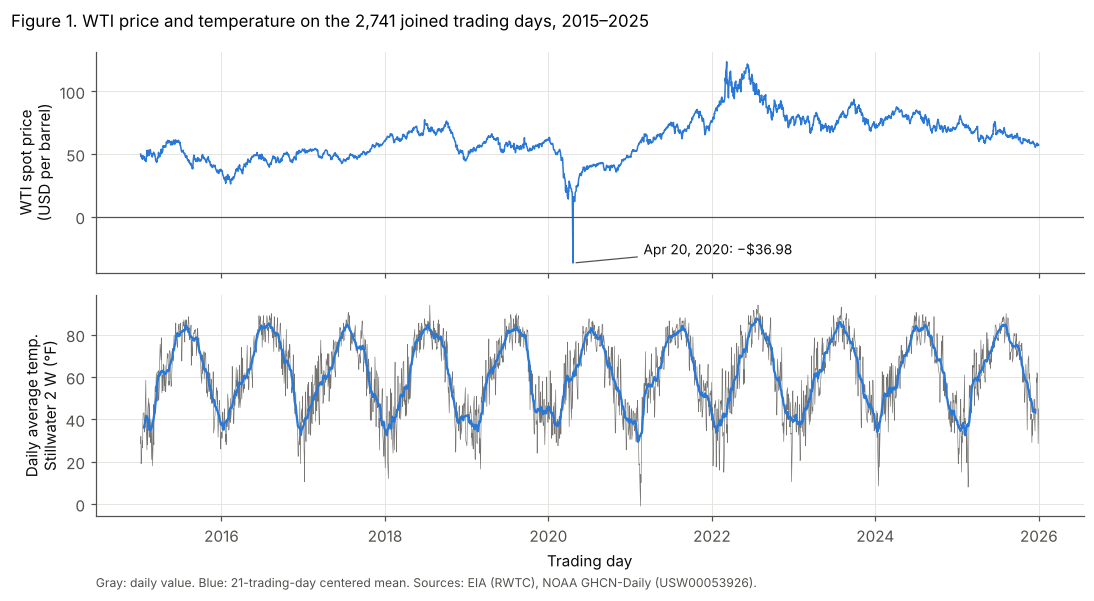

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)

axes[0].plot(df["date"], df["wti_price_usd_per_barrel"], color=BLUE, linewidth=1)
axes[0].axhline(0, color=MUTED, linewidth=0.8)
axes[0].set_ylabel("WTI spot price\n(USD per barrel)")
axes[0].annotate("Apr 20, 2020: −$36.98", xy=(pd.Timestamp("2020-04-20"), -36.98),
                 xytext=(pd.Timestamp("2021-03-01"), -30), color=INK, fontsize=9,
                 arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

axes[1].plot(df["date"], df["temp_avg_f"], color=MUTED, linewidth=0.4, alpha=0.8)
axes[1].plot(df["date"], df["temp_avg_f"].rolling(21, center=True).mean(), color=BLUE, linewidth=1.5)
axes[1].set_ylabel("Daily average temp.\nStillwater 2 W (°F)")
axes[1].set_xlabel("Trading day")

fig.suptitle("Figure 1. WTI price and temperature on the 2,741 joined trading days, 2015–2025",
             x=0.01, ha="left", fontsize=11)
axes[1].text(0.0, -0.32, "Gray: daily value. Blue: 21-trading-day centered mean. Sources: EIA (RWTC), NOAA GHCN-Daily (USW00053926).",
             transform=axes[1].transAxes, fontsize=8, color=MUTED)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_series_over_time.png", bbox_inches="tight")
plt.show()

Temperature repeats the same seasonal cycle each year. The oil price has a few long regimes (the 2015–2016 collapse, the April 2020 crash, the 2022 spike) that have no obvious counterpart in the temperature series.

## 6. Main Test: Same-Day Temperature and WTI Return

In [7]:
def spearman_row(data, x, y="daily_return_pct"):
    rho, p = stats.spearmanr(data[x], data[y])
    r, p_r = stats.pearsonr(data[x], data[y])
    return {"x": x, "y": y, "n": len(data), "pearson_r": r, "pearson_p": p_r,
            "spearman_rho": rho, "spearman_p": p}

corr_table = pd.DataFrame([
    spearman_row(analysis, "temp_avg_f"),
    spearman_row(analysis, "temp_anomaly_f"),
    spearman_row(analysis, "temp_range_f"),
    spearman_row(analysis, "temp_avg_f", "abs_return_pct"),
    spearman_row(analysis, "temp_anomaly_f", "abs_return_pct"),
])
corr_table.round(4)

,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,temp_avg_f,daily_return_pct,2739,-0.0073,0.7007,-0.0054,0.7782
1,temp_anomaly_f,daily_return_pct,2739,-0.0090,0.6361,-0.0168,0.3793
2,temp_range_f,daily_return_pct,2739,-0.0117,0.5392,0.0072,0.7063
3,temp_avg_f,abs_return_pct,2739,-0.0082,0.6677,0.0050,0.7927
4,temp_anomaly_f,abs_return_pct,2739,0.0265,0.1659,0.0240,0.2097


Both the Pearson and Spearman versions are shown because daily oil returns have heavy tails (March and April 2020 contain moves of ±25–50%). Spearman uses ranks, so a handful of extreme days cannot dominate it.

### Regression with autocorrelation-robust standard errors

Ordinary p-values assume each day is independent. Oil returns cluster in volatile periods, so the models below use Newey–West (HAC) standard errors with 5 lags (one trading week). Model B adds month fixed effects so that the temperature anomaly is compared only within the same calendar month.

In [8]:
HAC = dict(cov_type="HAC", cov_kwds={"maxlags": 5})
model_a = smf.ols("daily_return_pct ~ temp_avg_f", data=analysis).fit(**HAC)
model_b = smf.ols("daily_return_pct ~ temp_anomaly_f + C(month)", data=analysis).fit(**HAC)

def coef_summary(model, term, label):
    ci = model.conf_int().loc[term]
    return {"model": label, "term": term, "coef_pct_points_per_F": model.params[term],
            "ci_low": ci[0], "ci_high": ci[1], "p_value": model.pvalues[term],
            "r_squared": model.rsquared}

regression_table = pd.DataFrame([
    coef_summary(model_a, "temp_avg_f", "A: return ~ temp"),
    coef_summary(model_b, "temp_anomaly_f", "B: return ~ anomaly + month FE"),
])
regression_table.round(4)

,model,term,coef_pct_points_per_F,ci_low,ci_high,p_value,r_squared
0,A: return ~ temp,temp_avg_f,-0.0013,-0.0064,0.0038,0.6156,0.0001
1,B: return ~ anomaly + month FE,temp_anomaly_f,-0.0033,-0.0152,0.0085,0.5824,0.0040


In [9]:
slope = model_a.params["temp_avg_f"]
lo, hi = model_a.conf_int().loc["temp_avg_f"]
print(f"A 30°F swing (a cold winter day vs. a mild one) changes the expected daily return by "
      f"{30*slope:+.3f} percentage points (95% CI {30*lo:+.3f} to {30*hi:+.3f}).")
print(f"Typical daily move (median |return|): {analysis['abs_return_pct'].median():.2f} percentage points.")

A 30°F swing (a cold winter day vs. a mild one) changes the expected daily return by -0.039 percentage points (95% CI -0.191 to +0.113).
Typical daily move (median |return|): 1.35 percentage points.


### A permutation test that respects time structure

A standard permutation test shuffles days and breaks the autocorrelation in both series. Instead, I **circularly shift** the temperature-anomaly series against the returns by a random offset of at least 60 trading days. This keeps each series' own clustering intact and only destroys the day-to-day alignment between them. If the real alignment carries information, the observed |ρ| should sit in the tail of the shifted distribution.

In [10]:
N_SHIFTS = 2000
x = analysis["temp_anomaly_f"].to_numpy()
y_rank = stats.rankdata(analysis["daily_return_pct"])
x_rank = stats.rankdata(x)
observed_rho = np.corrcoef(x_rank, y_rank)[0, 1]

shifts = rng.integers(60, len(x) - 60, size=N_SHIFTS)
null_rho = np.array([np.corrcoef(np.roll(x_rank, s), y_rank)[0, 1] for s in shifts])
perm_p = (np.sum(np.abs(null_rho) >= abs(observed_rho)) + 1) / (N_SHIFTS + 1)

print(f"Observed Spearman rho (anomaly vs. return): {observed_rho:+.4f}")
print(f"Middle 95% of circular-shift null:          {np.percentile(null_rho, 2.5):+.4f} to {np.percentile(null_rho, 97.5):+.4f}")
print(f"Circular-shift permutation p-value:         {perm_p:.3f}")

Observed Spearman rho (anomaly vs. return): -0.0168
Middle 95% of circular-shift null:          -0.0370 to +0.0358
Circular-shift permutation p-value:         0.372


## 7. Is There a Pattern Hidden in the Extremes?

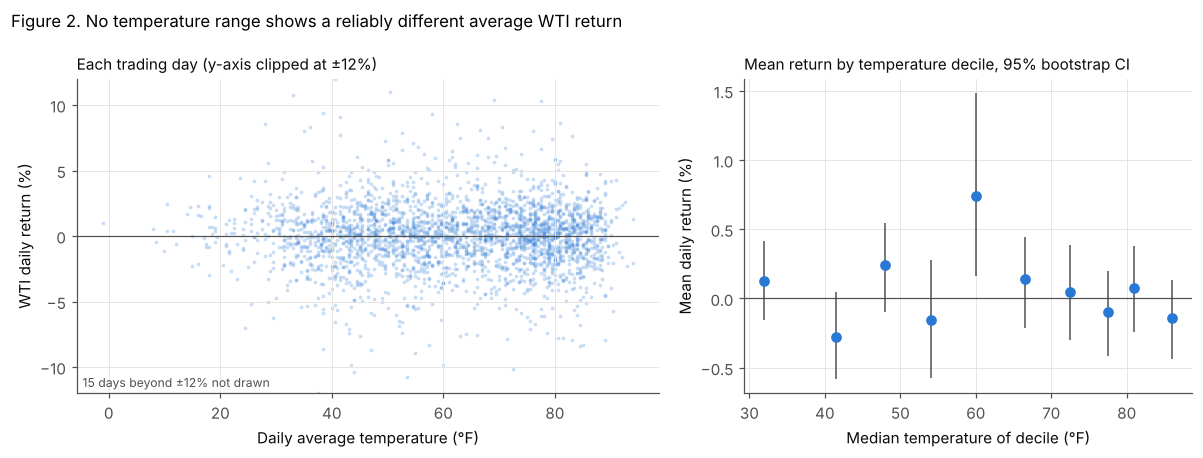

Deciles whose 95% CI excludes zero: [5]


In [11]:
analysis["temp_decile"] = pd.qcut(analysis["temp_avg_f"], 10, labels=False) + 1

def boot_mean_ci(values, n_boot=2000):
    values = np.asarray(values)
    boots = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return np.percentile(boots, [2.5, 97.5])

decile_rows = []
for decile, grp in analysis.groupby("temp_decile"):
    lo_ci, hi_ci = boot_mean_ci(grp["daily_return_pct"])
    decile_rows.append({"decile": decile, "temp_mid_f": grp["temp_avg_f"].median(),
                        "mean_return": grp["daily_return_pct"].mean(), "ci_low": lo_ci, "ci_high": hi_ci,
                        "n": len(grp)})
deciles = pd.DataFrame(decile_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.scatter(analysis["temp_avg_f"], analysis["daily_return_pct"], s=6, color=BLUE, alpha=0.25, linewidths=0)
ax.set_ylim(-12, 12)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xlabel("Daily average temperature (°F)")
ax.set_ylabel("WTI daily return (%)")
ax.set_title("Each trading day (y-axis clipped at ±12%)", fontsize=10, loc="left", color=INK)
n_clipped = (analysis["daily_return_pct"].abs() > 12).sum()
ax.text(0.01, 0.02, f"{n_clipped} days beyond ±12% not drawn", transform=ax.transAxes, fontsize=8, color=MUTED)

ax = axes[1]
ax.errorbar(deciles["temp_mid_f"], deciles["mean_return"],
            yerr=[deciles["mean_return"] - deciles["ci_low"], deciles["ci_high"] - deciles["mean_return"]],
            fmt="o", color=BLUE, ecolor=MUTED, elinewidth=1, capsize=0, markersize=6)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xlabel("Median temperature of decile (°F)")
ax.set_ylabel("Mean daily return (%)")
ax.set_title("Mean return by temperature decile, 95% bootstrap CI", fontsize=10, loc="left", color=INK)

fig.suptitle("Figure 2. No temperature range shows a reliably different average WTI return",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_return_vs_temperature.png", bbox_inches="tight")
plt.show()

print("Deciles whose 95% CI excludes zero:",
      deciles.loc[(deciles["ci_low"] > 0) | (deciles["ci_high"] < 0), "decile"].tolist())

### Cold and hot extremes compared with typical days

The physical story that motivated this project is strongest at the extremes: deep cold can freeze wellheads and pipeline equipment, and extreme heat can raise power demand. The next cell compares the coldest and hottest 5% of trading days with typical days, both for the direction of the move (return) and its size (absolute return). Mann–Whitney tests are used because returns are not normally distributed; the four p-values are Bonferroni-corrected.

In [12]:
typical = analysis.loc[analysis["temp_band"].eq("typical")]
band_rows, raw_p = [], []
for band in ["cold extreme", "hot extreme"]:
    grp = analysis.loc[analysis["temp_band"].eq(band)]
    for outcome in ["daily_return_pct", "abs_return_pct"]:
        p = stats.mannwhitneyu(grp[outcome], typical[outcome], alternative="two-sided").pvalue
        raw_p.append(p)
        band_rows.append({"band": band, "outcome": outcome, "n_band": len(grp),
                          "median_band": grp[outcome].median(), "median_typical": typical[outcome].median(),
                          "mean_band": grp[outcome].mean(), "mean_typical": typical[outcome].mean(),
                          "mann_whitney_p": p})
band_table = pd.DataFrame(band_rows)
band_table["bonferroni_p"] = np.minimum(band_table["mann_whitney_p"] * len(band_table), 1)
band_table.round(3)

,band,outcome,n_band,median_band,median_typical,mean_band,mean_typical,mann_whitney_p,bonferroni_p
0,cold extreme,daily_return_pct,142,0.424,0.065,0.353,0.057,0.040,0.16
1,cold extreme,abs_return_pct,142,1.265,1.353,1.650,1.937,0.446,1.00
2,hot extreme,daily_return_pct,150,0.231,0.065,0.046,0.057,0.660,1.00
3,hot extreme,abs_return_pct,150,1.433,1.353,1.657,1.937,0.769,1.00


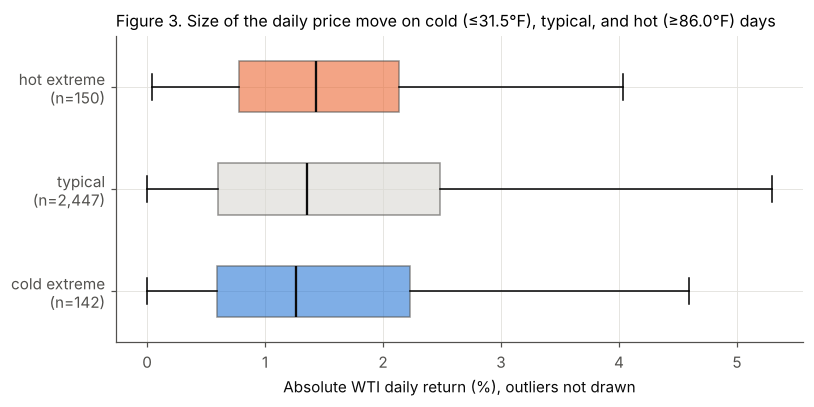

In [13]:
order = ["cold extreme", "typical", "hot extreme"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
data = [analysis.loc[analysis["temp_band"].eq(b), "abs_return_pct"] for b in order]
box_style = dict(widths=0.5, showfliers=False, patch_artist=True, medianprops=dict(color=INK, linewidth=1.5))
try:
    bp = ax.boxplot(data, orientation="horizontal", **box_style)  # matplotlib >= 3.10
except TypeError:
    bp = ax.boxplot(data, vert=False, **box_style)  # older matplotlib
for patch, color in zip(bp["boxes"], [BLUE, "#d9d8d3", ORANGE]):
    patch.set_facecolor(color); patch.set_alpha(0.6); patch.set_edgecolor(MUTED)
ax.set_yticks([1, 2, 3], [f"{b}\n(n={len(d):,})" for b, d in zip(order, data)])
ax.set_xlabel("Absolute WTI daily return (%), outliers not drawn")
ax.set_title(f"Figure 3. Size of the daily price move on cold (≤{COLD_CUT:.1f}°F), typical, and hot (≥{HOT_CUT:.1f}°F) days",
             fontsize=10.5, loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_extremes_abs_return.png", bbox_inches="tight")
plt.show()

## 8. Delayed Effects: Does Temperature Lead the Price?

A cold snap could affect prices with a delay, for example if production losses are reported days later. The cell below correlates each day's return with the temperature anomaly 0 to 5 trading days earlier. Testing six lags gives six chances at a false positive, so the significance threshold is Bonferroni-adjusted to 0.05 / 6 ≈ 0.0083.

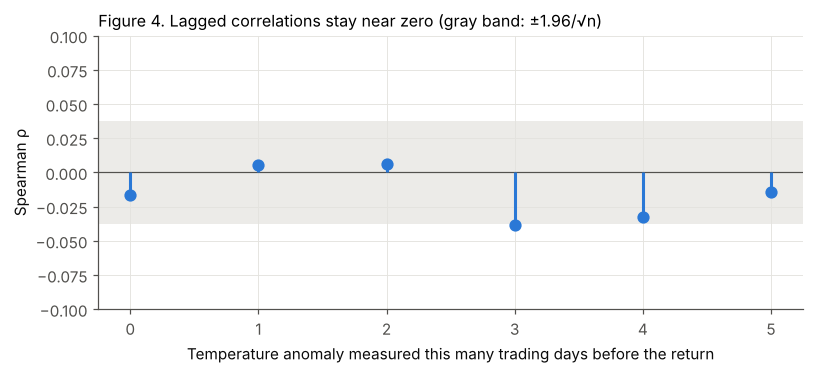

,lag_trading_days,n,spearman_rho,p_value,significant_after_bonferroni
0,0,2739,-0.0168,0.3793,False
1,1,2738,0.0052,0.7840,False
2,2,2737,0.0058,0.7601,False
3,3,2736,-0.0384,0.0446,False
4,4,2735,-0.0326,0.0885,False
5,5,2734,-0.0144,0.4515,False


In [14]:
MAX_LAG = 5
lag_rows = []
for lag in range(MAX_LAG + 1):
    pair = pd.DataFrame({"ret": analysis["daily_return_pct"],
                         "anom": analysis["temp_anomaly_f"].shift(lag)}).dropna()
    rho, p = stats.spearmanr(pair["anom"], pair["ret"])
    lag_rows.append({"lag_trading_days": lag, "n": len(pair), "spearman_rho": rho, "p_value": p,
                     "significant_after_bonferroni": p < 0.05 / (MAX_LAG + 1)})
lags = pd.DataFrame(lag_rows)

band95 = 1.96 / np.sqrt(len(analysis))
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.axhspan(-band95, band95, color="#e4e3df", alpha=0.7, linewidth=0)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.vlines(lags["lag_trading_days"], 0, lags["spearman_rho"], color=BLUE, linewidth=2)
ax.plot(lags["lag_trading_days"], lags["spearman_rho"], "o", color=BLUE, markersize=7)
ax.set_xlabel("Temperature anomaly measured this many trading days before the return")
ax.set_ylabel("Spearman ρ")
ax.set_ylim(-0.1, 0.1)
ax.set_title("Figure 4. Lagged correlations stay near zero (gray band: ±1.96/√n)", fontsize=10.5, loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_lag_correlations.png", bbox_inches="tight")
plt.show()
lags.round(4)

## 9. Sensitivity Checks

A conclusion is more trustworthy if it survives reasonable changes to the analysis. Each row below reruns the same-day Spearman test of temperature anomaly against return under a different choice.

In [15]:
def anomaly_rho(data):
    data = data.copy()
    data["anom"] = data["temp_avg_f"] - data.groupby(data["date"].dt.month)["temp_avg_f"].transform("mean")
    rho, p = stats.spearmanr(data["anom"], data["daily_return_pct"])
    return len(data), rho, p

covid = (analysis["date"] >= "2020-03-01") & (analysis["date"] <= "2020-06-30")
cases = {
    "Main analysis (April 20–21, 2020 excluded)": analysis,
    "All 2,741 rows (undefined returns kept)": df,
    "Exclude March–June 2020 entirely": analysis.loc[~covid],
    "2015–2019 only (before COVID)": analysis.loc[analysis["year"] <= 2019],
    "2021–2025 only (after COVID)": analysis.loc[analysis["year"] >= 2021],
    "Winter months only (Dec–Feb)": analysis.loc[analysis["month"].isin([12, 1, 2])],
    "Summer months only (Jun–Aug)": analysis.loc[analysis["month"].isin([6, 7, 8])],
}
sensitivity = pd.DataFrame(
    [(label, *anomaly_rho(data)) for label, data in cases.items()],
    columns=["sample", "n", "spearman_rho", "p_value"],
)
sensitivity.round(4)

,sample,n,spearman_rho,p_value
0,"Main analysis (April 20–21, 2020 excluded)",2739,-0.0168,0.3793
1,"All 2,741 rows (undefined returns kept)",2741,-0.0171,0.3711
2,Exclude March–June 2020 entirely,2656,-0.0186,0.3386
3,2015–2019 only (before COVID),1258,-0.0203,0.4727
4,2021–2025 only (after COVID),1233,-0.0154,0.5890
5,Winter months only (Dec–Feb),664,-0.0397,0.3074
6,Summer months only (Jun–Aug),704,-0.0434,0.2496


## 10. Case Study: Winter Storm Uri (February 2021)

The most extreme cold in the study period came during Winter Storm Uri. On February 16, 2021, the average temperature at Stillwater 2 W was **−1°F**. This is the scenario the project question is built around, so it deserves a direct look.

In [16]:
uri = df.loc[(df["date"] >= "2021-02-04") & (df["date"] <= "2021-02-26"),
             ["date", "temp_avg_f", "wti_price_usd_per_barrel", "daily_return_pct"]]
print(uri.round({"daily_return_pct": 2}).to_string(index=False))

before = df.loc[df["date"].eq("2021-02-05"), "wti_price_usd_per_barrel"].item()
peak = uri.loc[uri["date"].between("2021-02-08", "2021-02-19"), "wti_price_usd_per_barrel"].max()
jan4 = df.loc[df["date"].eq("2021-01-04"), "wti_price_usd_per_barrel"].item()
print(f"\nBefore the storm, WTI had already risen from ${jan4:.2f} (Jan 4) to ${before:.2f} (Feb 5), "
      f"{100*(before/jan4 - 1):+.1f}%.")
print(f"WTI rose from ${before:.2f} (Feb 5) to a peak of ${peak:.2f} during the storm week "
      f"({100*(peak/before - 1):+.1f}%).")
print("Median |return| on Feb 8–19, 2021:",
      round(uri.loc[uri["date"].between("2021-02-08", "2021-02-19"), "daily_return_pct"].abs().median(), 2),
      "% vs. full-sample median", round(analysis["abs_return_pct"].median(), 2), "%")

      date  temp_avg_f  wti_price_usd_per_barrel  daily_return_pct
2021-02-04        44.5                     56.19              0.93
2021-02-05        41.0                     56.80              1.09
2021-02-08        24.5                     57.95              2.02
2021-02-09        18.5                     58.34              0.67
2021-02-10        19.0                     58.69              0.60
2021-02-11        18.0                     58.22             -0.80
2021-02-12        14.5                     59.50              2.20
2021-02-16        -1.0                     60.07              0.96
2021-02-17        14.0                     61.09              1.70
2021-02-18        10.0                     60.40             -1.13
2021-02-19        16.0                     59.12             -2.12
2021-02-22        45.0                     61.67              4.31
2021-02-23        50.5                     61.66             -0.02
2021-02-24        49.5                     63.21              

Prices rose during the storm, but the output above shows they were already rising for the month before it. Two pieces of context come from outside this data set and are not tested here: early 2021 was a period of post-COVID demand recovery, and Uri also forced oil production shut-ins in Texas, a supply shock far beyond one Oklahoma weather station. A single week cannot separate "cold near Cushing" from everything else happening at the same time. This case is consistent with the idea that extreme cold *can* matter through supply, but it does not show that local temperature drives prices.

## 11. How Small an Effect Could This Data Have Detected?

A null result is only informative if the test had enough power. With *n* = 2,739, a two-sided test at α = 0.05 with 80% power detects a correlation of roughly |ρ| ≥ (1.96 + 0.84) / √(n − 3).

In [17]:
n = len(analysis)
mde = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) / np.sqrt(n - 3)
print(f"Minimum detectable |correlation| at 80% power: {mde:.3f}")
print(f"That is {100*mde**2:.2f}% of the variance in daily returns.")
print(f"Observed same-day Spearman rho with temperature level:   {corr_table.loc[0, 'spearman_rho']:+.4f}")
print(f"Observed same-day Spearman rho with temperature anomaly: {corr_table.loc[1, 'spearman_rho']:+.4f}")

Minimum detectable |correlation| at 80% power: 0.054
That is 0.29% of the variance in daily returns.
Observed same-day Spearman rho with temperature level:   -0.0054
Observed same-day Spearman rho with temperature anomaly: -0.0168


## 12. Who the Trading-Day Grain Leaves Out

The left join keeps one row per WTI trading day, so weather on weekends and market holidays never enters the analysis. That's the right grain for a price-change question, but it isn't neutral: some of the most extreme weather days fall on days the market was closed. The cell below reads the raw NOAA file and checks which of the coldest and hottest calendar days made it into the analysis.

In [18]:
noaa = pd.read_csv("data/raw/noaa_stillwater_daily_2015_2025.csv",
                   usecols=["DATE", "TMIN", "TMAX"], parse_dates=["DATE"])
noaa["temp_avg_f"] = (noaa["TMIN"] + noaa["TMAX"]) / 2
noaa["weekday"] = noaa["DATE"].dt.day_name()
noaa["in_analysis"] = noaa["DATE"].isin(analysis["date"])

print(f"NOAA calendar days recorded:      {len(noaa):,}")
print(f"  in the analysis sample:         {noaa['in_analysis'].sum():,}")
print(f"  left out, any reason:           {(~noaa['in_analysis']).sum():,}")
weekend = noaa["DATE"].dt.dayofweek >= 5
print(f"  of those, Saturdays and Sundays: {(~noaa['in_analysis'] & weekend).sum():,}")

cols = ["DATE", "weekday", "temp_avg_f", "in_analysis"]
coldest = noaa.dropna(subset=["temp_avg_f"]).nsmallest(10, "temp_avg_f")[cols]
hottest = noaa.dropna(subset=["temp_avg_f"]).nlargest(10, "temp_avg_f")[cols]
print("\nTen coldest calendar days, 2015–2025:")
print(coldest.to_string(index=False))
print("\nTen hottest calendar days, 2015–2025:")
print(hottest.to_string(index=False))
print(f"\nIn the analysis: {coldest['in_analysis'].sum()} of the 10 coldest days, "
      f"{hottest['in_analysis'].sum()} of the 10 hottest, {noaa['in_analysis'].mean():.0%} of all days.")

NOAA calendar days recorded:      4,013
  in the analysis sample:         2,739
  left out, any reason:           1,274
  of those, Saturdays and Sundays: 1,146

Ten coldest calendar days, 2015–2025:
      DATE   weekday  temp_avg_f  in_analysis
2021-02-15    Monday        -3.0        False
2021-02-16   Tuesday        -1.0         True
2024-01-14    Sunday         0.0        False
2024-01-15    Monday         3.0        False
2021-02-14    Sunday         5.5        False
2025-02-19 Wednesday         8.0         True
2024-01-16   Tuesday         8.5         True
2016-12-18    Sunday         9.5        False
2021-02-18  Thursday        10.0         True
2017-01-06    Friday        10.5         True

Ten hottest calendar days, 2015–2025:
      DATE   weekday  temp_avg_f  in_analysis
2018-07-20    Friday        94.0         True
2022-07-26   Tuesday        94.0         True
2023-08-02 Wednesday        93.0         True
2017-07-22  Saturday        92.5        False
2023-08-03  Thursday     

The coldest day in the period, **February 15, 2021 (−3°F average)**, was Presidents' Day, and February 14 was a Sunday, so neither has a WTI price. The January 2024 cold snap on January 14 and 15 also fell on a Sunday and on Martin Luther King Jr. Day. The extreme-cold tests in Section 7 therefore miss several of the most severe cold days. The market's response to them can show up only on the next trading day, which the lag analysis in Section 8 partly covers.

## 13. Findings

**What the data support (known):**

1. **No detectable same-day association.** Across 2,739 trading days, daily average temperature near Cushing is essentially uncorrelated with the WTI daily return. The Spearman ρ is about −0.005 for temperature level and −0.017 for temperature anomaly, and neither is statistically significant. The HAC regression slope for temperature is a tiny fraction of a percentage point per °F, and its confidence interval includes zero.
2. **The null holds up.** The result does not change when the April 2020 rows are added back, when the COVID shock is removed, before and after COVID, or within winter or summer alone (Section 9). The circular-shift permutation test agrees.
3. **There is enough data to rule out a meaningful linear effect.** The test could detect |ρ| ≈ 0.054 (about 0.3% of return variance). Any same-day linear association that exists is smaller than that.
4. **Extreme days do not reliably differ either.** After correcting for multiple tests, the coldest and hottest 5% of days do not have significantly different returns or move sizes than typical days (Section 7). One of the ten temperature deciles has a 95% interval that excludes zero, which is about what chance alone produces with ten intervals (it is a middle decile near 60°F, not an extreme). No lag from 0 to 5 trading days is significant after the Bonferroni correction; the strongest, lag 3 (ρ ≈ −0.04, raw p ≈ 0.045), would not survive it (Section 8).

**What remains uncertain (suspected, not shown):**

- Cold-extreme days have a somewhat higher *mean* return than typical days in this sample, but the difference is not statistically reliable and rests on 142 days (Mann–Whitney p = 0.04 before correction, 0.16 after). A larger sample, or a regional temperature index instead of one station, could show a small effect that this design misses.
- Winter Storm Uri coincided with rising prices, but the storm's effect on Texas production and the broader 2021 recovery are confounded with local temperature.
- The analysis tests linear and rank associations, extremes, and short lags. A nonlinear threshold effect, for example only below 0°F (which happened on very few days), cannot be tested with this many events.

**Bottom line:** within 2015–2025, the temperature at one station 20 miles from Cushing gives no usable information about the next WTI price move. WTI is a global benchmark priced by worldwide supply, demand, and storage, and the question's premise (local weather as a signal) does not hold at the daily level.

In [19]:
summary = {
    "analysis_days": len(analysis),
    "spearman_rho_temp_level": round(corr_table.loc[0, "spearman_rho"], 4),
    "spearman_p_temp_level": round(corr_table.loc[0, "spearman_p"], 3),
    "spearman_rho_anomaly": round(corr_table.loc[1, "spearman_rho"], 4),
    "spearman_p_anomaly": round(corr_table.loc[1, "spearman_p"], 3),
    "hac_slope_per_F": round(model_a.params["temp_avg_f"], 4),
    "hac_slope_p": round(model_a.pvalues["temp_avg_f"], 3),
    "anomaly_month_fe_p": round(model_b.pvalues["temp_anomaly_f"], 3),
    "circular_shift_p": round(perm_p, 3),
    "min_detectable_rho": round(mde, 3),
    "smallest_bonferroni_p_extremes": round(band_table["bonferroni_p"].min(), 3),
    "any_lag_significant": bool(lags["significant_after_bonferroni"].any()),
}
pd.Series(summary, name="value").to_frame()

,value
analysis_days,2739
spearman_rho_temp_level,-0.0054
spearman_p_temp_level,0.778
spearman_rho_anomaly,-0.0168
spearman_p_anomaly,0.379
hac_slope_per_F,-0.0013
hac_slope_p,0.616
anomaly_month_fe_p,0.582
circular_shift_p,0.372
min_detectable_rho,0.054


## 14. Reproducibility Check

In [20]:
expected_figures = [
    "fig1_series_over_time.png",
    "fig2_return_vs_temperature.png",
    "fig3_extremes_abs_return.png",
    "fig4_lag_correlations.png",
]
for name in expected_figures:
    path = FIG_DIR / name
    assert path.exists(), f"Missing figure {name}"
    print(f"{name:34s} {path.stat().st_size/1024:6.0f} KB")
print(f"Random seed: {SEED}. The notebook ran from top to bottom without errors.")

fig1_series_over_time.png             238 KB
fig2_return_vs_temperature.png        163 KB
fig3_extremes_abs_return.png           50 KB
fig4_lag_correlations.png              55 KB
Random seed: 405. The notebook ran from top to bottom without errors.


## AI Use Note

*To be completed by the author — see report §8.*